Открытие графического окна для локализации корня...


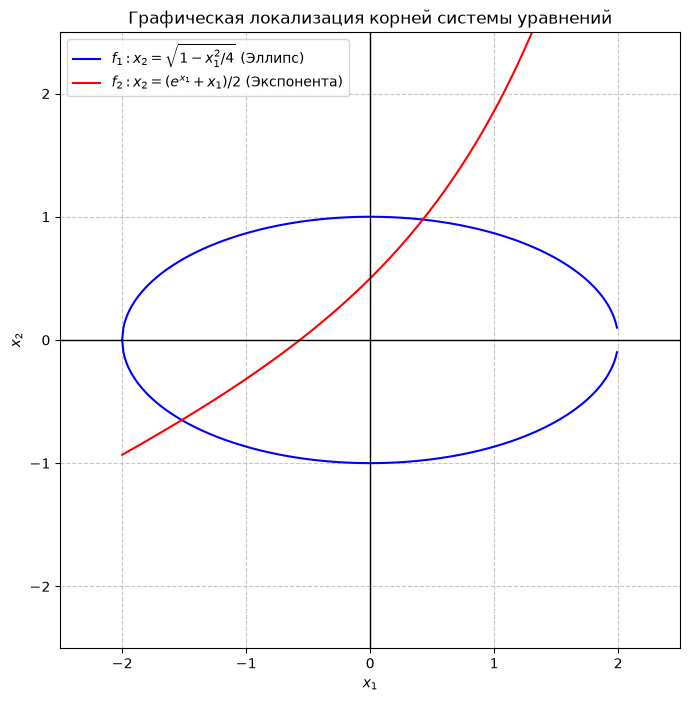

In [3]:
def graphical_localization():

    x1_vals = []
    x2_eq1_plus = []
    x2_eq1_minus = []
    x2_eq2 = []

    step = 0.01
    x = -2.0

    while x <= 2.0:
        x1_vals.append(x)

        val = 1.0 - (x**2) / 4.0

        if val < 0: val = 0.0

        x2_eq1_plus.append(math.sqrt(val))
        x2_eq1_minus.append(-math.sqrt(val))
        
        x2_eq2.append((math.exp(x) + x) / 2.0)
        
        x += step

    plt.figure(figsize=(8, 8))
    plt.plot(x1_vals, x2_eq1_plus, 'b-', label=r'$f_1: x_2 = \sqrt{1 - x_1^2/4}$ (Эллипс)')
    plt.plot(x1_vals, x2_eq1_minus, 'b-') 
    plt.plot(x1_vals, x2_eq2, 'r-', label='$f_2: x_2 = (e^{x_1} + x_1)/2$ (Экспонента)')

    plt.axhline(0, color='black', linewidth=1)
    plt.axvline(0, color='black', linewidth=1)

    plt.grid(True, linestyle='--', alpha=0.7)
    plt.title('Графическая локализация корней системы уравнений')
    plt.xlabel('$x_1$')
    plt.ylabel('$x_2$')
    plt.legend()
    plt.xlim(-2.5, 2.5)
    plt.ylim(-2.5, 2.5)
    
    plt.show()

def main():
    print("Открытие графического окна для локализации корня...")

    graphical_localization()

if __name__ == '__main__':
    main()

In [ ]:
import math
import sys
import os

sys.path.append(os.path.abspath('..'))

from lab1.lab_1_1_LU import lu_decomposition, solve_lu, det_lu

class NonLinearSystem:
    def __init__(self):
        self.name = "Вариант 13 (a = 2)"
        self.eq1_str = "x1^2 / 4 + x2^2 - 1 = 0"
        self.eq2_str = "2*x2 - e^(x1) - x1 = 0"

        self.f1 = lambda x1, x2: (x1**2) / 4.0 + x2**2 - 1.0
        self.f2 = lambda x1, x2: 2.0 * x2 - math.exp(x1) - x1

        self.df1_dx1 = lambda x1, x2: x1 / 2.0
        self.df1_dx2 = lambda x1, x2: 2.0 * x2
        self.df2_dx1 = lambda x1, x2: -math.exp(x1) - 1.0
        self.df2_dx2 = lambda x1, x2: 2.0

        self.phi1 = lambda x1, x2: math.log(2.0 * x2 - x1)
        self.phi2 = lambda x1, x2: math.sqrt(max(0.0, 1.0 - (x1**2) / 4.0))

        self.dphi1_dx1 = lambda x1, x2: -1.0 / (2.0 * x2 - x1)
        self.dphi1_dx2 = lambda x1, x2: 2.0 / (2.0 * x2 - x1)

        def dphi2_dx1_safe(x1):
            val = 1.0 - (x1**2) / 4.0
            if val <= 0:
                return 0.0
            return -x1 / (4.0 * math.sqrt(val))
            
        self.dphi2_dx1 = dphi2_dx1_safe
        self.dphi2_dx2 = lambda x1, x2: 0.0

    def get_F(self, x):
        return [self.f1(x[0], x[1]), self.f2(x[0], x[1])]

    def get_Jacobian(self, x):
        x1, x2 = x[0], x[1]
        return [
            [self.df1_dx1(x1, x2), self.df1_dx2(x1, x2)],
            [self.df2_dx1(x1, x2), self.df2_dx2(x1, x2)]
        ]

    def get_Phi(self, x):
        return [self.phi1(x[0], x[1]), self.phi2(x[0], x[1])]

    def get_Phi_Jacobian(self, x):
        
        x1, x2 = x[0], x[1]
        return [
            [self.dphi1_dx1(x1, x2), self.dphi1_dx2(x1, x2)],
            [self.dphi2_dx1(x1), self.dphi2_dx2(x1, x2)]
        ]


def newton_system(sys_eq, x0, eps, max_iter=500):
    x_curr = [float(val) for val in x0]
    history = []
    
    for k in range(max_iter):
        F_val = sys_eq.get_F(x_curr)
        J_matrix = sys_eq.get_Jacobian(x_curr)
        
        L, U, P, swaps_count = lu_decomposition(J_matrix)
        det_J = float(det_lu(U, swaps_count))
        
        if abs(det_J) < 1e-15:
            raise ZeroDivisionError(f"Матрица Якоби вырождена на шаге {k} (det J = 0)!")
            
        neg_F = [-val for val in F_val]
        delta_x = [float(val) for val in solve_lu(L, U, P, neg_F)]
        
        norm_delta = max(abs(dx) for dx in delta_x)
        norm_F = max(abs(f) for f in F_val)
        
        history.append({
            'k': k, 'x': list(x_curr), 'F': F_val, 'det_J': det_J,
            'delta_x': delta_x, 'norm_delta': norm_delta, 'norm_F': norm_F
        })
        
        x_next = [x_curr[i] + delta_x[i] for i in range(len(x_curr))]
        
        if norm_delta <= eps or norm_F <= eps:
            x_curr = x_next
            break
            
        x_curr = x_next
        
    return x_curr, len(history), history


def simple_iteration_system(sys_eq, x0, eps, max_iter=500):
    x_curr = [float(val) for val in x0]
    history = []
    
    J_Phi = sys_eq.get_Phi_Jacobian(x_curr)
    
    a, b = J_Phi[0][0], J_Phi[0][1]
    c, d = J_Phi[1][0], J_Phi[1][1]
    
    trace = a + d
    det = a * d - b * c
    discriminant = trace**2 - 4 * det
    
    if discriminant >= 0:
        lambda_1 = abs((trace + math.sqrt(discriminant)) / 2.0)
        lambda_2 = abs((trace - math.sqrt(discriminant)) / 2.0)
        q = max(lambda_1, lambda_2)
    else:
        q = math.sqrt(abs(det))
    
    if q >= 1.0:
        q = 0.99
    
    for k in range(max_iter):
        x_next = sys_eq.get_Phi(x_curr)
        delta_x = [x_next[i] - x_curr[i] for i in range(len(x_curr))]
        norm_delta = max(abs(dx) for dx in delta_x)
        F_val = sys_eq.get_F(x_curr)
        
        history.append({
            'k': k, 'x': list(x_curr), 'Phi': x_next,
            'norm_delta': norm_delta, 'F': F_val
        })
        
        eps_adj = eps if q <= 0.5 else ((1.0 - q) / q) * eps
        
        if norm_delta <= eps_adj:
            x_curr = x_next
            break
            
        x_curr = x_next
        
    return x_curr, len(history), history, q


def print_history_table(history, method_type):
    n_total = len(history)
    for i, item in enumerate(history):
        if n_total > 15 and 5 <= i < n_total - 5:
            if i == 5:
                if method_type == 'newton':
                    print(f"{'...':<4} | {'...':<10} | {'...':<10} | {'...':<10} | {'...':<12} | {'...':<12}")
                else:
                    print(f"{'...':<4} | {'...':<10} | {'...':<10} | {'...':<12} | {'...':<12} | {'...':<12}")
            continue
            
        if method_type == 'newton':
            print(f"{item['k']:<4} | {item['x'][0]:<10.6f} | {item['x'][1]:<10.6f} | {item['det_J']:<10.4f} | {item['norm_delta']:<12.3e} | {item['norm_F']:<12.3e}")
        else:
            print(f"{item['k']:<4} | {item['x'][0]:<10.6f} | {item['x'][1]:<10.6f} | {item['norm_delta']:<12.3e} | {item['F'][0]:<12.3e} | {item['F'][1]:<12.3e}")


def main():
    eps = 0.001
    sys_eq = NonLinearSystem()
    
    print("=" * 85)
    print(" ЛАБОРАТОРНАЯ РАБОТА № 2.2: РЕШЕНИЕ СИСТЕМ НЕЛИНЕЙНЫХ УРАВНЕНИЙ (ВАРИАНТ 13)")
    print("=" * 85)
    print("Исследуемая система уравнений:")
    print(f"  f1(x1, x2) = {sys_eq.eq1_str}")
    print(f"  f2(x1, x2) = {sys_eq.eq2_str}\n")
    
    x0 = [0.4, 0.9]  
    
    print(f"[Начальное приближение с графика]: x1_0 = {x0[0]}, x2_0 = {x0[1]}")
    print(f"Заданная точность eps = {eps}\n")
    
    x_newton, k_newt, hist_newton = newton_system(sys_eq, x0, eps)
    
    print("-" * 85)
    print(" ИТЕРАЦИОННЫЙ ПРОЦЕСС МЕТОДА НЬЮТОНА (с LU-разложением матрицы Якоби из Лаб 1.1)")
    print("-" * 85)
    print(f"{'k':<4} | {'x1^(k)':<10} | {'x2^(k)':<10} | {'det J':<10} | {'||delta_x||':<12} | {'||F||':<12}")
    print("-" * 85)
    print_history_table(hist_newton, 'newton')
    print(f"-> Уточненный корень: x1* = {x_newton[0]:.6f}, x2* = {x_newton[1]:.6f} (Итераций: {k_newt})")
    
    x_iter, k_iter, hist_iter, q_val = simple_iteration_system(sys_eq, x0, eps)
    
    print("\n" + "-" * 85)
    print(f" ИТЕРАЦИОННЫЙ ПРОЦЕСС МЕТОДА ПРОСТЫХ ИТЕРАЦИЙ (Аналитическая оценка q = {q_val:.4f})")
    print("-" * 85)
    print(f"{'k':<4} | {'x1^(k)':<10} | {'x2^(k)':<10} | {'||delta_x||':<12} | {'f1(x)':<12} | {'f2(x)':<12}")
    print("-" * 85)
    print_history_table(hist_iter, 'iter')
    print(f"-> Уточненный корень: x1* = {x_iter[0]:.6f}, x2* = {x_iter[1]:.6f} (Итераций: {k_iter})")
    
    f_newt = max(abs(f) for f in sys_eq.get_F(x_newton))
    f_iter = max(abs(f) for f in sys_eq.get_F(x_iter))
    
    print("\n" + "=" * 85)
    print(" СВОДНАЯ ТАБЛИЦА СРАВНЕНИЯ МЕТОДОВ ДЛЯ СИСТЕМЫ НЕЛИНЕЙНЫХ УРАВНЕНИЙ (ВАРИАНТ 13)")
    print("=" * 85)
    print(f"{'Метод':<30} | {'Итераций':<10} | {'x1*':<10} | {'x2*':<10} | {'Невязка ||F||':<15}")
    print("-" * 85)
    print(f"{'1. Метод Ньютона (с LU)':<30} | {k_newt:<10} | {x_newton[0]:<10.6f} | {x_newton[1]:<10.6f} | {f_newt:<15.3e}")
    print(f"{f'2. Простые итерации (q={q_val:.2f})':<30} | {k_iter:<10} | {x_iter[0]:<10.6f} | {x_iter[1]:<10.6f} | {f_iter:<15.3e}")
    print("=" * 85)

if __name__ == '__main__':
    main()

 ЛАБОРАТОРНАЯ РАБОТА № 2.2: РЕШЕНИЕ СИСТЕМ НЕЛИНЕЙНЫХ УРАВНЕНИЙ (ВАРИАНТ 13)
Исследуемая система уравнений:
  f1(x1, x2) = x1^2 / 4 + x2^2 - 1 = 0
  f2(x1, x2) = 2*x2 - e^(x1) - x1 = 0

[Начальное приближение с графика]: x1_0 = 0.4, x2_0 = 0.9
Заданная точность eps = 0.001

-------------------------------------------------------------------------------------
 ИТЕРАЦИОННЫЙ ПРОЦЕСС МЕТОДА НЬЮТОНА (с LU-разложением матрицы Якоби из Лаб 1.1)
-------------------------------------------------------------------------------------
k    | x1^(k)     | x2^(k)     | det J      | ||delta_x||  | ||F||       
-------------------------------------------------------------------------------------
0    | 0.400000   | 0.900000   | 4.8853     | 8.027e-02    | 1.500e-01   
1    | 0.427576   | 0.980269   | 5.3947     | 3.093e-03    | 6.633e-03   
2    | 0.424909   | 0.977177   | 5.3683     | 6.210e-06    | 1.134e-05   
-> Уточненный корень: x1* = 0.424902, x2* = 0.977172 (Итераций: 3)

----------------------